# Class distribution and mask analysis

This notebook reads the raw datasets and does not change any files. It counts classes, reads RDD2022 XML boxes, and samples masks to measure crack-pixel percentages.

## Step 0: Import packages and set the raw-data folder

The path is written as a raw string so Windows backslashes work correctly.

In [1]:
import os
import glob
import random
import xml.etree.ElementTree as ET
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

RAW_ROOT = r"D:\Infosys springboards\data\raw"
random.seed(42)

print("Raw data folder:", RAW_ROOT)
if not os.path.isdir(RAW_ROOT):
    print("The raw-data folder is missing. Check RAW_ROOT before continuing.")

Raw data folder: D:\Infosys springboards\data\raw


## Step 0 continued: Find dataset folders and image files

The helper functions search recursively. They keep original dataset images and skip Crack500 crops and model predictions.

In [2]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".jpe", ".png", ".bmp", ".tif", ".tiff")

def find_dataset_folder(dataset_name):
    if not os.path.isdir(RAW_ROOT):
        print(f"Raw data folder is missing: {RAW_ROOT}")
        return None
    names = os.listdir(RAW_ROOT)
    match = next((name for name in names if name.lower() == dataset_name.lower()), None)
    if match is None:
        print(f"Dataset folder is missing: {os.path.join(RAW_ROOT, dataset_name)}")
        return None
    return os.path.join(RAW_ROOT, match)

def find_images(folder):
    if not folder:
        return []
    paths = glob.glob(os.path.join(folder, "**", "*"), recursive=True)
    return [path for path in paths if os.path.isfile(path) and os.path.splitext(path)[1].lower() in IMAGE_EXTENSIONS]

dataset_paths = {name: find_dataset_folder(name) for name in ("sdnet2018", "concrete_crack_cls", "rdd2022", "crack500", "cfd")}
print("Dataset folders:")
for name, folder in dataset_paths.items():
    print(f"{name}: {folder if folder else 'missing'}")

Dataset folders:
sdnet2018: D:\Infosys springboards\data\raw\SDNET2018
concrete_crack_cls: D:\Infosys springboards\data\raw\concrete_crack_cls
rdd2022: D:\Infosys springboards\data\raw\rdd2022
crack500: D:\Infosys springboards\data\raw\crack500
cfd: D:\Infosys springboards\data\raw\cfd


## Step 1: Count SDNET2018 cracked and uncracked images

The final folder names CD, CP, and CW mean cracked; UD, UP, and UW mean uncracked. We count each label separately for the D, P, and W groups.

SDNET2018 counts:
D {'cracked': 2025, 'uncracked': 11595}
P {'cracked': 2608, 'uncracked': 21726}
W {'cracked': 3851, 'uncracked': 14287}


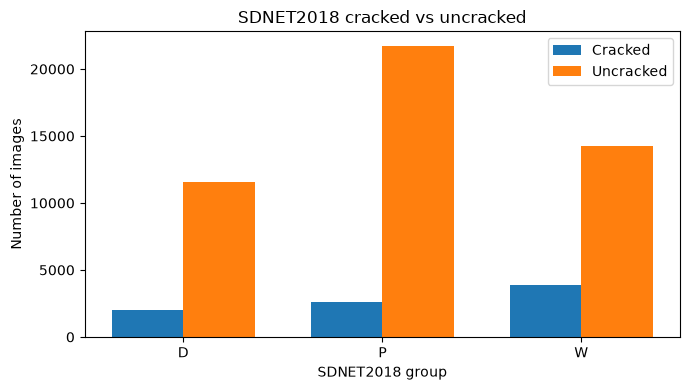

In [3]:
sdnet_counts = {group: Counter({"cracked": 0, "uncracked": 0}) for group in ("D", "P", "W")}
sdnet_folder = dataset_paths["sdnet2018"]
if sdnet_folder:
    sdnet_images = find_images(sdnet_folder)
    for image_path in sdnet_images:
        parts = os.path.relpath(image_path, sdnet_folder).split(os.sep)
        group = parts[0].upper()
        class_folder = os.path.basename(os.path.dirname(image_path)).upper()
        if group in sdnet_counts and class_folder in ("CD", "CP", "CW"):
            sdnet_counts[group]["cracked"] += 1
        elif group in sdnet_counts and class_folder in ("UD", "UP", "UW"):
            sdnet_counts[group]["uncracked"] += 1
    print("SDNET2018 counts:")
    for group, counts in sdnet_counts.items():
        print(group, dict(counts))
else:
    sdnet_images = []
    print("SDNET2018 folder is missing; no counts were made.")

groups = list(sdnet_counts)
positions = np.arange(len(groups))
bar_width = 0.36
plt.figure(figsize=(7, 4))
plt.bar(positions - bar_width / 2, [sdnet_counts[group]["cracked"] for group in groups], bar_width, label="Cracked")
plt.bar(positions + bar_width / 2, [sdnet_counts[group]["uncracked"] for group in groups], bar_width, label="Uncracked")
plt.xticks(positions, groups)
plt.xlabel("SDNET2018 group")
plt.ylabel("Number of images")
plt.title("SDNET2018 cracked vs uncracked")
plt.legend()
plt.tight_layout()
plt.show()

## Step 2: Count Concrete Crack Positive and Negative images

The Positive and Negative folders are the two class labels. The chart compares the number of images in each folder.

Concrete Crack counts: {'Positive': 20000, 'Negative': 20000}


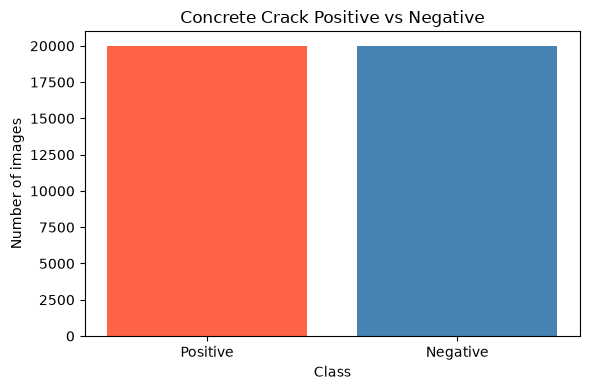

In [4]:
concrete_counts = Counter()
concrete_folder = dataset_paths["concrete_crack_cls"]
if concrete_folder:
    for label in ("Positive", "Negative"):
        class_folder = os.path.join(concrete_folder, label)
        if not os.path.isdir(class_folder):
            print(f"Class folder is missing: {class_folder}")
            concrete_counts[label] = 0
            continue
        paths = glob.glob(os.path.join(class_folder, "**", "*"), recursive=True)
        concrete_counts[label] = sum(1 for path in paths if os.path.isfile(path) and os.path.splitext(path)[1].lower() in IMAGE_EXTENSIONS)
    print("Concrete Crack counts:", dict(concrete_counts))
else:
    print("Concrete Crack folder is missing; no counts were made.")

plt.figure(figsize=(6, 4))
plt.bar(list(concrete_counts), list(concrete_counts.values()), color=["tomato", "steelblue"])
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.title("Concrete Crack Positive vs Negative")
plt.tight_layout()
plt.show()

## Step 3: Count RDD2022 damage boxes by class

Each XML object is one labeled damage box. This reads every XML file and counts how many annotation files contain zero boxes. Test images without XML are counted separately because missing XML does not prove an image has no damage.

Found 38385 RDD2022 XML files.
Damage boxes per class: {'Block crack': 3, 'D00': 26016, 'D01': 179, 'D0w0': 1, 'D10': 11830, 'D11': 45, 'D20': 10617, 'D40': 6544, 'D43': 793, 'D44': 5057, 'D50': 3581, 'Repair': 1046}
Images with an XML file containing zero boxes: 11724
Images without an XML annotation: 9035
XML files that could not be read: 0


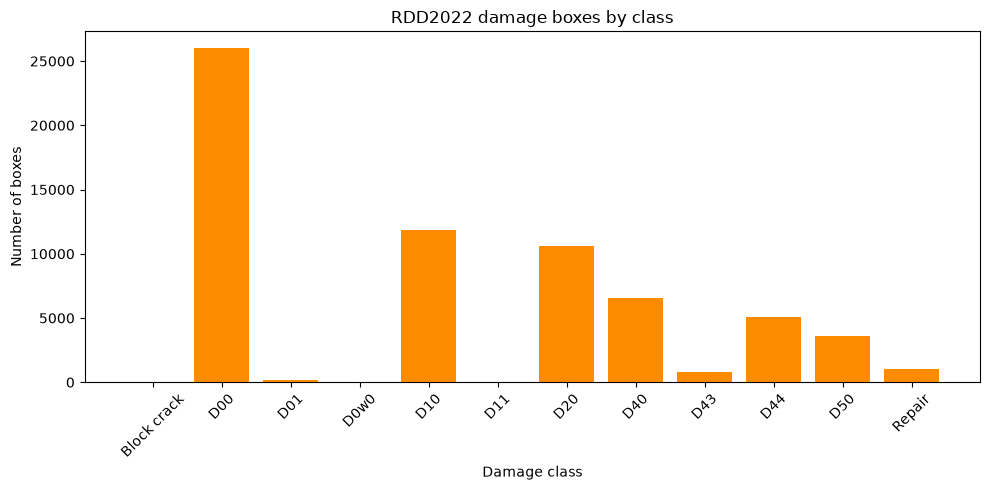

In [5]:
rdd_folder = dataset_paths["rdd2022"]
damage_class_counts = Counter()
zero_box_xml_count = 0
xml_error_count = 0
if rdd_folder:
    xml_files = glob.glob(os.path.join(rdd_folder, "**", "*.xml"), recursive=True)
    print(f"Found {len(xml_files)} RDD2022 XML files.")
    for xml_path in xml_files:
        try:
            root = ET.parse(xml_path).getroot()
            objects = root.findall("object")
            if not objects:
                zero_box_xml_count += 1
            for item in objects:
                class_name = item.findtext("name", default="unknown").strip()
                damage_class_counts[class_name] += 1
        except (ET.ParseError, OSError) as error:
            xml_error_count += 1
            print(f"Could not read XML {xml_path}: {error}")

    rdd_images = [path for path in find_images(rdd_folder) if "images" in [part.lower() for part in path.split(os.sep)]]
    annotated_images = sum(1 for path in rdd_images if os.path.isfile(os.path.join(os.path.dirname(os.path.dirname(path)), "annotations", "xmls", os.path.splitext(os.path.basename(path))[0] + ".xml")))
    images_without_xml = len(rdd_images) - annotated_images
    print("Damage boxes per class:", dict(sorted(damage_class_counts.items())))
    print("Images with an XML file containing zero boxes:", zero_box_xml_count)
    print("Images without an XML annotation:", images_without_xml)
    print("XML files that could not be read:", xml_error_count)
else:
    xml_files = []
    rdd_images = []
    images_without_xml = 0
    print("RDD2022 folder is missing; XML counts were not made.")

plt.figure(figsize=(10, 5))
if damage_class_counts:
    class_names = sorted(damage_class_counts)
    plt.bar(class_names, [damage_class_counts[name] for name in class_names], color="darkorange")
    plt.xticks(rotation=45)
else:
    plt.text(0.5, 0.5, "No damage boxes found", ha="center", va="center")
plt.xlabel("Damage class")
plt.ylabel("Number of boxes")
plt.title("RDD2022 damage boxes by class")
plt.tight_layout()
plt.show()

## Step 4: Measure crack pixels in 50 random masks

A mask pixel greater than zero is treated as a crack pixel. For Crack500 and CFD, the percentage is `crack pixels / all pixels * 100`. Up to 50 masks are sampled from each dataset.

crack500: measured 50 mask(s) out of 500 available
  Crack pixel percent range: 0.380% to 6.880%
cfd: measured 50 mask(s) out of 118 available
  Crack pixel percent range: 0.352% to 6.219%


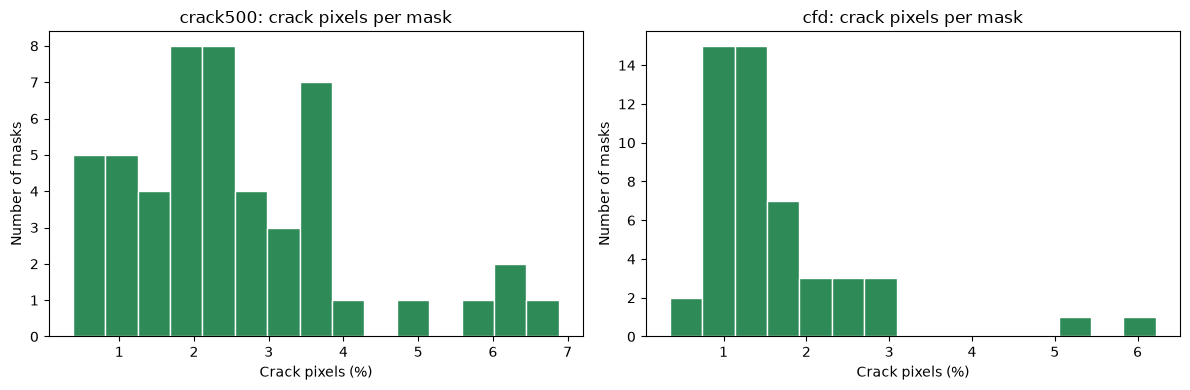

In [6]:
mask_percentages = {"crack500": [], "cfd": []}
mask_sample_counts = {}
mask_class_counts = {}

for name in ("crack500", "cfd"):
    folder = dataset_paths[name]
    if not folder:
        print(f"{name} folder is missing; mask percentages were not calculated.")
        mask_sample_counts[name] = 0
        mask_class_counts[name] = {"mask_has_crack": 0, "mask_has_no_crack": 0}
        continue

    if name == "crack500":
        masks = glob.glob(os.path.join(folder, "**", "traindata", "**", "*_mask.png"), recursive=True)
        masks += glob.glob(os.path.join(folder, "**", "testdata", "**", "*_mask.png"), recursive=True)
        masks += glob.glob(os.path.join(folder, "**", "valdata", "**", "*_mask.png"), recursive=True)
    else:
        mask_folder = next((os.path.join(folder, entry) for entry in os.listdir(folder) if entry.lower() == "masks"), None)
        masks = glob.glob(os.path.join(mask_folder, "**", "*"), recursive=True) if mask_folder else []
        masks = [path for path in masks if os.path.isfile(path) and os.path.splitext(path)[1].lower() == ".png"]

    masks = sorted(set(path for path in masks if os.path.isfile(path)))
    chosen_masks = random.sample(masks, min(50, len(masks)))
    for mask_path in chosen_masks:
        try:
            with Image.open(mask_path) as mask:
                pixels = np.asarray(mask.convert("L"))
            crack_percent = float(np.count_nonzero(pixels > 0) / pixels.size * 100)
            mask_percentages[name].append(crack_percent)
        except (OSError, ValueError) as error:
            print(f"Could not read mask {mask_path}: {error}")

    mask_sample_counts[name] = len(mask_percentages[name])
    has_crack = sum(value > 0 for value in mask_percentages[name])
    mask_class_counts[name] = {"mask_has_crack": has_crack, "mask_has_no_crack": len(mask_percentages[name]) - has_crack}
    print(f"{name}: measured {len(mask_percentages[name])} mask(s) out of {len(masks)} available")
    if mask_percentages[name]:
        print(f"  Crack pixel percent range: {min(mask_percentages[name]):.3f}% to {max(mask_percentages[name]):.3f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, name in zip(axes, ("crack500", "cfd")):
    if mask_percentages[name]:
        axis.hist(mask_percentages[name], bins=15, color="seagreen", edgecolor="white")
    else:
        axis.text(0.5, 0.5, "No masks found", ha="center", va="center")
    axis.set_title(f"{name}: crack pixels per mask")
    axis.set_xlabel("Crack pixels (%)")
    axis.set_ylabel("Number of masks")
plt.tight_layout()
plt.show()

## Step 5: Review the class distribution summary

The imbalance ratio is the largest class count divided by the smallest non-zero class count. For Crack500 and CFD, the classes below describe whether each sampled mask contains any crack pixels.

In [7]:
def get_imbalance_ratio(counts):
    nonzero_counts = [count for count in counts.values() if count > 0]
    if len(nonzero_counts) < 2:
        return "N/A"
    return round(max(nonzero_counts) / min(nonzero_counts), 2)

sdnet_total_counts = Counter()
for group_counts in sdnet_counts.values():
    sdnet_total_counts.update(group_counts)

summary_rows = []
summary_inputs = {
    "sdnet2018": (sdnet_total_counts, "Counts combine D, P, and W; chart shows each group."),
    "concrete_crack_cls": (concrete_counts, "Positive and Negative folder names are used as class labels."),
    "rdd2022": (damage_class_counts, f"{zero_box_xml_count} annotated image(s) have zero boxes; {images_without_xml} image(s) have no XML; {xml_error_count} XML read error(s)."),
    "crack500": (Counter(mask_class_counts.get("crack500", {})), f"Mask pixel statistics use {mask_sample_counts.get('crack500', 0)} random mask(s); percentage histogram is above."),
    "cfd": (Counter(mask_class_counts.get("cfd", {})), f"Mask pixel statistics use {mask_sample_counts.get('cfd', 0)} random mask(s); percentage histogram is above."),
}

for name, (counts, note) in summary_inputs.items():
    if dataset_paths[name] is None:
        note = "Dataset folder is missing. " + note
    summary_rows.append({
        "Dataset": name,
        "Classes": ", ".join(str(label) for label in counts.keys()) if counts else "No class counts",
        "Count per class": dict(counts),
        "Imbalance ratio": get_imbalance_ratio(counts),
        "Notes": note,
    })

summary_table = pd.DataFrame(summary_rows, columns=["Dataset", "Classes", "Count per class", "Imbalance ratio", "Notes"])
summary_table

,Dataset,Classes,Count per class,Imbalance ratio,Notes
0,sdnet2018,"cracked, uncracked","{'cracked': 8484, 'uncracked': 47608}",5.61,"Counts combine D, P, and W; chart shows each g..."
1,concrete_crack_cls,"Positive, Negative","{'Positive': 20000, 'Negative': 20000}",1.0,Positive and Negative folder names are used as...
2,rdd2022,"D10, D00, D20, Repair, D40, Block crack, D44, ...","{'D10': 11830, 'D00': 26016, 'D20': 10617, 'Re...",26016.0,11724 annotated image(s) have zero boxes; 9035...
3,crack500,"mask_has_crack, mask_has_no_crack","{'mask_has_crack': 50, 'mask_has_no_crack': 0}",N/A,Mask pixel statistics use 50 random mask(s); p...
4,cfd,"mask_has_crack, mask_has_no_crack","{'mask_has_crack': 50, 'mask_has_no_crack': 0}",N/A,Mask pixel statistics use 50 random mask(s); p...
